# PCA of land-cover patches & autoencoder super-resolution

## 0. Setup

In [63]:
import os, random, time, warnings
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")      # hides TensorFlow's INFO/WARNING chatter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
import tifffile

from sklearn.decomposition import PCA, KernelPCA
from sklearn.cluster import KMeans
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import silhouette_score, adjusted_rand_score, confusion_matrix, ConfusionMatrixDisplay

import tensorflow as tf

Image.MAX_IMAGE_PIXELS = None          # Copernicus images can be large

DATA_DIR = "data"
SEED     = 50

def set_seed(s):
    random.seed(s); np.random.seed(s); tf.random.set_seed(s)

set_seed(SEED)
tf.get_logger().setLevel("ERROR")
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


# Part 1 — PCA of land-cover patches

## 1. Idea

A 200 × 200 × 3 patch is one point in a 120 000-dimensional space. PCA finds the orthonormal directions along which such points vary most. With the training mean $\mu$ and the eigenvectors $\mathbf{w}_1,\mathbf{w}_2,\mathbf{w}_3$ of the covariance matrix that belong to its three largest eigenvalues, every patch $\mathbf{x}$ becomes three numbers:

$$ \mathbf{z} = W_3^{\top}(\mathbf{x}-\mu), \qquad W_3 = [\mathbf{w}_1\;\mathbf{w}_2\;\mathbf{w}_3] $$

PCA never sees the labels. If the classes form separate clouds in $(z_1,z_2,z_3)$, then land cover is the dominant source of variation in the pixels.

Design choices:

* **Block-average by 5 first** (200 × 200 × 3 → 40 × 40 × 3 = 4 800 features). It keeps the colour and the texture at a reasonable scale, discards pixel-level noise, and makes PCA fast. `DOWNSAMPLE = 1` uses the raw pixels.
* **PCA is fitted on training patches only** (left 70 % of every image). Test patches (right 30 %) are projected with the *same* $W_3$ and drawn as triangles. If they fall into the training clouds, the 3-D structure is not just memorised scenery.
* The class labels are used **only to colour the points** and to score the clusters afterwards.

In [64]:
# ---------------------------- Part 1 configuration -----------------------------
CLASSES       = ["forest", "urban", "ocean"]    # sub-folders of DATA_DIR;
PATCH         = 200                              # patch size in pixels
STRIDE        = 200                              # = PATCH -> patches do not overlap
TEST_FRACTION = 0.30                             # right-hand 30 % of every image is the test part
MAX_PER_CLASS = 300                              # training patches per class (before balancing)
DOWNSAMPLE    = 5                                # block-average factor applied before PCA
KNN_K         = 5

palette      = ["#2ca02c", "#d62728", "#1f77b4"]
CLASS_COLORS = {c: palette[i] for i, c in enumerate(CLASSES)}

# ------------------------- loading  --------------------------

def list_images(folder):
    # Return a sorted list of all supported image files in the folder.
    folder = Path(folder)
    return sorted(p for p in folder.glob("*") if p.suffix.lower() == ".tiff") if folder.exists() else []

def load_image(path):
    # Return (rgb uint8 [H,W,3], valid-pixel mask [H,W]).
    path = Path(path)
    if path.suffix.lower() in (".tif", ".tiff"):
        arr = tifffile.imread(str(path))
    else:
        im = Image.open(path)
        arr = np.asarray(im if im.mode in ("L", "RGB", "RGBA") else im.convert("RGB"))
    if arr.ndim == 3 and arr.shape[0] < arr.shape[-1]:          # (bands,H,W) -> (H,W,bands)
        arr = np.moveaxis(arr, 0, -1)
    if arr.ndim == 2:                                            # grayscale -> 3 channels
        arr = np.repeat(arr[..., None], 3, axis=-1)
    if arr.shape[-1] > 4:
        warnings.warn(f"{path.name}: {arr.shape[-1]} bands, using the first 3 as RGB")
    valid = arr[..., 3] > 0 if arr.shape[-1] == 4 else np.ones(arr.shape[:2], bool)   # alpha = nodata
    arr = arr[..., :3]
    if arr.dtype != np.uint8:                                    # e.g. 16-bit export -> 8 bit
        warnings.warn(f"{path.name}: {arr.dtype} data, stretched to 8 bit (2-98 percentile)")
        lo, hi = np.percentile(arr, (2, 98))
        arr = np.clip((arr.astype(np.float32) - lo) / max(hi - lo, 1e-6) * 255, 0, 255).astype(np.uint8)
    valid &= arr.any(axis=-1)                                    # pure black = nodata
    return arr, valid

def patch_ok(p, m):
    # Return True if the patch p is valid (not nodata, not saturated white cloud / snow).
    if m.mean() < 0.98:
        return False
    if p.mean() > 215 and p.std() < 25:
        return False
    return True

def sample_patches(img, valid, x_range, cap, rng):
    # Random non-overlapping PATCH x PATCH tiles from columns x_range of the image.
    H = img.shape[0]
    x0, x1 = x_range
    coords = [(y, x) for y in range(0, H - PATCH + 1, STRIDE)
                     for x in range(x0, x1 - PATCH + 1, STRIDE)]
    rng.shuffle(coords)
    out = []
    for y, x in coords:
        if len(out) >= cap:
            break
        p = img[y:y + PATCH, x:x + PATCH]
        if patch_ok(p, valid[y:y + PATCH, x:x + PATCH]):
            out.append(p)
    return out

for c in CLASSES:
    print(f"{c:7s}:", [p.name for p in list_images(Path(DATA_DIR) / c)])

forest : ['forest1.tiff', 'forest2.tiff', 'forest3.tiff', 'forest4.tiff', 'forest5.tiff', 'forest6.tiff', 'forest7.tiff', 'forest8.tiff']
urban  : ['urban1.tiff', 'urban2.tiff', 'urban3.tiff', 'urban4.tiff', 'urban5.tiff', 'urban6.tiff', 'urban7.tiff', 'urban8.tiff']
ocean  : ['ocean1.tiff', 'ocean2.tiff', 'ocean3.tiff', 'ocean4.tiff']


## 2. Patches from the three land covers

The split is spatial: the left 70 % of each image gives the training patches, the right 30 % the test patches. Neighbouring patches look alike, so a random split would put near-copies on both sides. The classes are balanced (same number of patches per class), so no cluster is large merely because it has more points.

In [65]:
def build_dataset(data_dir):
    # Return (X, y, scene) for train and for test, with balanced classes.
    rng = np.random.default_rng(SEED)
    max_test = int(MAX_PER_CLASS * TEST_FRACTION / (1 - TEST_FRACTION))
    tr  = {c: [] for c in range(len(CLASSES))}; te  = {c: [] for c in range(len(CLASSES))}
    str_ = {c: [] for c in range(len(CLASSES))}; ste = {c: [] for c in range(len(CLASSES))}
    for label, cls in enumerate(CLASSES):
        files = list_images(Path(data_dir) / cls)
        if not files:
            raise FileNotFoundError(f"No images in {Path(data_dir) / cls}. See 'Data layout' at the top of the notebook.")
        for f in files:
            img, valid = load_image(f)
            split = int(img.shape[1] * (1 - TEST_FRACTION))
            a = sample_patches(img, valid, (0, split),            int(np.ceil(MAX_PER_CLASS / len(files))), rng)
            b = sample_patches(img, valid, (split, img.shape[1]), int(np.ceil(max_test / len(files))),      rng)
            tr[label] += a; te[label] += b
            str_[label] += [f"{cls}/{f.stem}"] * len(a); ste[label] += [f"{cls}/{f.stem}"] * len(b)
            print(f"{cls:7s} {f.name:28s} {img.shape[1]}x{img.shape[0]} px -> {len(a):4d} train, {len(b):4d} test patches")
            del img, valid
    def balance(pool, srcs):
        # Return balanced (X, y, scene) from the pool of patches.
        n = min(len(v) for v in pool.values())
        X, y, s = [], [], []
        for label, patches in pool.items():
            idx = rng.choice(len(patches), n, replace=False)
            X += [patches[i] for i in idx]; y += [label] * n; s += [srcs[label][i] for i in idx]
        return np.stack(X), np.array(y), np.array(s)
    return balance(tr, str_), balance(te, ste)

(X_tr, y_tr, s_tr), (X_te, y_te, s_te) = build_dataset(DATA_DIR)
print(f"\ntrain: {X_tr.shape}   test: {X_te.shape}")
print("patches per class  train:", np.bincount(y_tr), "  test:", np.bincount(y_te))

forest  forest1.tiff                 450x282 px ->    1 train,    0 test patches
forest  forest2.tiff                 461x305 px ->    1 train,    0 test patches
forest  forest3.tiff                 450x323 px ->    1 train,    0 test patches


/tmp/ipykernel_78584/1148663287.py:37: UserWarning: forest1.tiff: uint16 data, stretched to 8 bit (2-98 percentile)
  warnings.warn(f"{path.name}: {arr.dtype} data, stretched to 8 bit (2-98 percentile)")
/tmp/ipykernel_78584/1148663287.py:37: UserWarning: forest2.tiff: uint16 data, stretched to 8 bit (2-98 percentile)
  warnings.warn(f"{path.name}: {arr.dtype} data, stretched to 8 bit (2-98 percentile)")
/tmp/ipykernel_78584/1148663287.py:37: UserWarning: forest3.tiff: uint16 data, stretched to 8 bit (2-98 percentile)
  warnings.warn(f"{path.name}: {arr.dtype} data, stretched to 8 bit (2-98 percentile)")


forest  forest4.tiff                 1376x1254 px ->   24 train,   12 test patches
forest  forest5.tiff                 1521x1452 px ->   35 train,   14 test patches
forest  forest6.tiff                 1756x1725 px ->   38 train,   16 test patches
forest  forest7.tiff                 1309x1314 px ->   24 train,    6 test patches
forest  forest8.tiff                 1192x1158 px ->   20 train,    5 test patches
urban   urban1.tiff                  337x216 px ->    1 train,    0 test patches
urban   urban2.tiff                  306x213 px ->    1 train,    0 test patches
urban   urban3.tiff                  307x187 px ->    0 train,    0 test patches
urban   urban4.tiff                  1001x1007 px ->   15 train,    5 test patches


/tmp/ipykernel_78584/1148663287.py:37: UserWarning: urban1.tiff: uint16 data, stretched to 8 bit (2-98 percentile)
  warnings.warn(f"{path.name}: {arr.dtype} data, stretched to 8 bit (2-98 percentile)")
/tmp/ipykernel_78584/1148663287.py:37: UserWarning: urban2.tiff: uint16 data, stretched to 8 bit (2-98 percentile)
  warnings.warn(f"{path.name}: {arr.dtype} data, stretched to 8 bit (2-98 percentile)")
/tmp/ipykernel_78584/1148663287.py:37: UserWarning: urban3.tiff: uint16 data, stretched to 8 bit (2-98 percentile)
  warnings.warn(f"{path.name}: {arr.dtype} data, stretched to 8 bit (2-98 percentile)")


urban   urban5.tiff                  1124x1119 px ->   15 train,    5 test patches
urban   urban6.tiff                  1112x1084 px ->   15 train,    5 test patches
urban   urban7.tiff                  1294x1217 px ->   24 train,    6 test patches
urban   urban8.tiff                  1017x1009 px ->   15 train,    5 test patches
ocean   ocean1.tiff                  2500x2340 px ->   75 train,   32 test patches
ocean   ocean2.tiff                  2500x2387 px ->   75 train,   32 test patches
ocean   ocean3.tiff                  2500x2378 px ->   75 train,   32 test patches
ocean   ocean4.tiff                  1466x1452 px ->   35 train,   14 test patches

train: (258, 200, 200, 3)   test: (78, 200, 200, 3)
patches per class  train: [86 86 86]   test: [26 26 26]


## 3. Features and PCA

Each patch is block-averaged, scaled to $[0,1]$ and flattened into one feature vector. `PCA` centres the data itself, so the mean patch is subtracted automatically.

In [66]:
def to_features(X, f=DOWNSAMPLE, chunk=128):
    # uint8 patches [N,H,W,3] -> float32 feature matrix [N, (H/f)*(W/f)*3] in [0,1].
    assert PATCH % f == 0, "PATCH must be divisible by DOWNSAMPLE"
    out = []
    for i in range(0, len(X), chunk):
        b = X[i:i + chunk].astype(np.float32) / 255.0
        n, h, w, c = b.shape
        out.append(b.reshape(n, h // f, f, w // f, f, c).mean(axis=(2, 4)).reshape(n, -1))
    return np.concatenate(out)

F_tr, F_te = to_features(X_tr), to_features(X_te)
FH = PATCH // DOWNSAMPLE
print("feature matrix  train:", F_tr.shape, "  test:", F_te.shape, f"  ({FH} x {FH} x 3 per patch)")

# PCA with 3 components: fitted on the training patches, applied to both sets
pca = PCA(n_components=3, random_state=SEED).fit(F_tr)
Z_tr, Z_te = pca.transform(F_tr), pca.transform(F_te)
print("explained variance ratio of PC1..PC3:", np.round(pca.explained_variance_ratio_, 3),
      f"  -> total {pca.explained_variance_ratio_.sum():.1%}")

feature matrix  train: (258, 4800)   test: (78, 4800)   (40 x 40 x 3 per patch)
explained variance ratio of PC1..PC3: [0.815 0.087 0.011]   -> total 91.4%


## 4. The 3-D picture

Circles are training patches, triangles are test patches that were projected afterwards. The cloud is shown as a rotatable 3D plot, because a singular viewing angle could hide a separation that another one would reveal. The 2-D projections underneath show the three pairs of axes; crosses mark the class centroids of the training patches.

In [67]:
try:
    import plotly.express as px
    d = pd.concat([
        pd.DataFrame(dict(PC1=Z_tr[:, 0], PC2=Z_tr[:, 1], PC3=Z_tr[:, 2], land_cover=np.array(CLASSES)[y_tr], scene=s_tr, split="train")),
        pd.DataFrame(dict(PC1=Z_te[:, 0], PC2=Z_te[:, 1], PC3=Z_te[:, 2], land_cover=np.array(CLASSES)[y_te], scene=s_te, split="test"))])
    fig = px.scatter_3d(d, x="PC1", y="PC2", z="PC3", color="land_cover", symbol="split", hover_name="scene",
                        color_discrete_map=CLASS_COLORS, opacity=.8, height=650)
    fig.update_traces(marker_size=3)
    fig.show()
except ImportError:
    print("plotly is not installed, skipping 3-D plot")

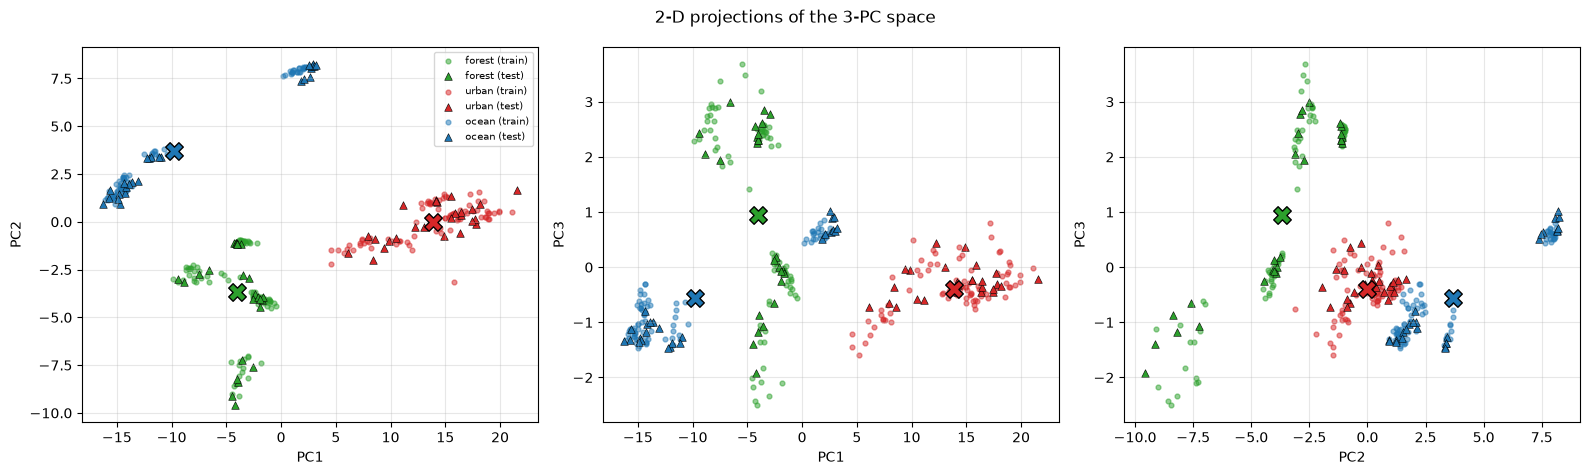

In [68]:
def projections(Ztr, ytr, Zte, yte, title):
    pairs = [(0, 1), (0, 2), (1, 2)]
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
    for ax, (a, b) in zip(axes, pairs):
        for k, cls in enumerate(CLASSES):
            m = ytr == k
            ax.scatter(Ztr[m, a], Ztr[m, b], s=12, alpha=.5, color=CLASS_COLORS[cls], label=f"{cls} (train)")
            ax.scatter(Zte[yte == k, a], Zte[yte == k, b], s=30, marker="^", edgecolor="k", linewidths=.4,
                       color=CLASS_COLORS[cls], label=f"{cls} (test)")
            ax.scatter(*Ztr[m][:, [a, b]].mean(0), marker="X", s=160, color=CLASS_COLORS[cls], edgecolor="k", zorder=5)
        ax.set_xlabel(f"PC{a + 1}"); ax.set_ylabel(f"PC{b + 1}"); ax.grid(alpha=.3)
    axes[0].legend(fontsize=7)
    plt.suptitle(title); plt.tight_layout(); plt.show()

projections(Z_tr, y_tr, Z_te, y_te, "2-D projections of the 3-PC space")

## 5. Observations

The images do cluster, albeit not ideally. The urban cluster is the most gathered of the cloud, with every patch from its images concentrating in the same area, albeit some patches do centre more densely together. The more spread out patches also appear to direct themselves towards the forest cloud, which itself has the most spread out points over three groups, one being more concentrated than the other two. The ocean patches have two distinct clusters, but they are the densest of the whole cloud, which is most probably due to the prevelance of either darker or lighter tones of water. The best 2D representation of clustering is the plot of PC1 vs PC2, the most impactful of the principal components, meaning the images are easy to differentiate.

# Part 2 — Autoencoder super-resolution

## 6. Method

The network is trained on synthetic pairs. High-resolution (HR) patches are cut from the image itself, shrunk by `AveragePooling` to make the low-resolution (LR) input, and the network has to reproduce the HR patch:

$$ \mathbf{x}_{LR} = D(\mathbf{x}_{HR}), \qquad \hat{\mathbf{x}}_{HR} = f_{\mathbf w}(\mathbf{x}_{LR}) $$

$D$ is block averaging by `SCALE` (2 × 2 for `SCALE = 2`). Because the true HR image is known for a held-out part of the scene, we can measure whether the network enhances the resolution (PSNR, SSIM, power spectrum) instead of judging by eye.

| model | network input | architecture | loss |
|---|---|---|---|
| **nearest / bicubic** | LR | no learning, the baselines to beat | – |
| **M1** | LR | conv 16 → pool → conv 8 → pool → conv 8 → up → conv 8 → up → conv 16 → up → conv, auoencoder adapted to RGB | binary cross-entropy |
| **M2** | bicubic-up-scaled LR | the same idea with skip connections and a residual output: the net predicts only the missing detail that is added to the bicubic image | L1 (mean absolute error) |

**Spatial split of the scene**: columns 0–55 % → training, 55–70 % → validation (early stopping), 70–100 % → test, never touched while training.

**Honest framing.** The network can only learn what detail typically looks like in this image and re-draw it; it cannot recover information that the sensor never recorded. Whether that learned prior helps is exactly what the test band measures.

test.tiff: 2171 x 2060 px


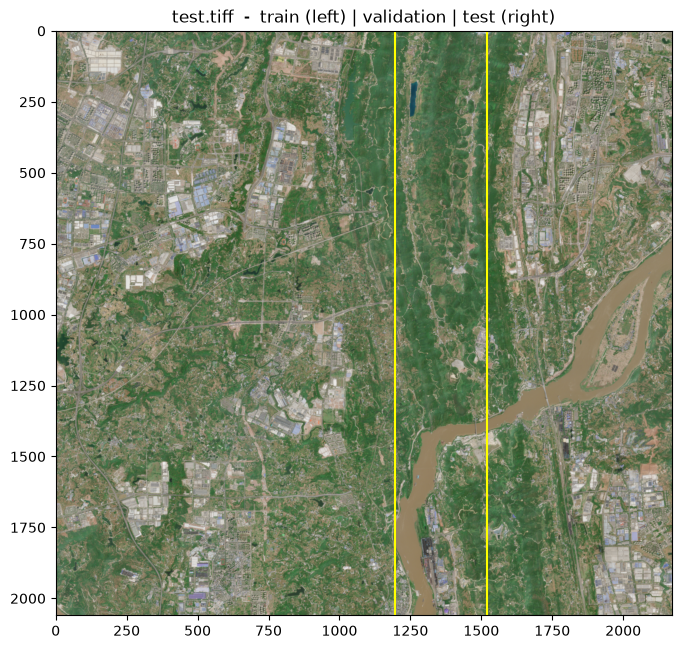

In [69]:
# ---------------------------- Part 2 configuration -----------------------------
SR_IMAGE      = f"{DATA_DIR}/test.tiff"   # any EO image; falls back to the first image found under data/
SCALE         = 2                         # up-scaling factor: 2 or 4
LR_PATCH      = 32                        # LR patch size (must be divisible by 4)
HR_PATCH      = LR_PATCH * SCALE
TRAIN_END, VAL_END = 0.55, 0.70           # column fractions: train | validation | test
SR_STRIDE     = 32                        # step (HR px) between overlapping training patches
MAX_SR_TRAIN  = 4000                      # cap on training patches
MAX_SR_VAL    = 600
MIN_STD       = 3.0                       # skip nearly uniform patches (std in 0-255 units): nothing to learn there
AUGMENT       = True                      # random flips / 90-degree rotations of the training patches
SR_EPOCHS     = 30
SR_BATCH      = 32
SR_PATIENCE   = 6                         # early stopping on validation loss
BASE_FILTERS  = 32                        # width of M2 (use 16 on a slow CPU)
TEST_CROP     = 256                       # HR size of each test crop (multiple of 4 * SCALE)
N_TEST_CROPS  = 8
ROI_SIZE      = 128                       # native-resolution window for the last experiment (multiple of 4)
ROI           = None                      # (y, x) of its top-left corner, or None = most detailed window of the test band
RUN_ABLATION  = False                     # True: also train M2 variants (skips / residual / loss switched off)

assert SCALE in (2, 4) and LR_PATCH % 4 == 0 and ROI_SIZE % 4 == 0

# ---------------------------------- the image ----------------------------------
sr_path = Path(SR_IMAGE)
if not sr_path.exists():
    pool = (list_images(DATA_DIR) + list_images(Path(DATA_DIR) / "urban") + list_images(Path(DATA_DIR) / "forest")
            + list_images(Path(DATA_DIR) / "ocean"))
    if not pool:
        raise FileNotFoundError(f"{SR_IMAGE} not found and no images under {DATA_DIR}/")
    sr_path = pool[0]
    print(f"{SR_IMAGE} not found - using {sr_path} instead")

hr_img, hr_valid = load_image(sr_path)
H, W, _ = hr_img.shape
print(f"{sr_path.name}: {W} x {H} px")

s = max(1, max(H, W) // 1600)
plt.figure(figsize=(8, 8 * H / W)); plt.imshow(hr_img[::s, ::s], extent=(0, W, H, 0))
for xf, lab in [(TRAIN_END, "train | val"), (VAL_END, "val | test")]:
    plt.axvline(xf * W, color="yellow", lw=1.5)
plt.title(f"{sr_path.name}  -  train (left) | validation | test (right)"); plt.show()

## 7. Training and test data

* **Training / validation:** random `HR_PATCH × HR_PATCH` windows of the training / validation band, skipping nodata, clouds and nearly uniform windows (open water has little detail to learn from). Training windows overlap by half (`SR_STRIDE`); validation windows do not overlap.
* **Test:** `N_TEST_CROPS` crops of `TEST_CROP × TEST_CROP` pixels from the test band. These are shrunk to LR, super-resolved, and compared with the original crop.

train patches (2268, 64, 64, 3)   val patches (160, 64, 64, 3)   test crops (8, 256, 256, 3)


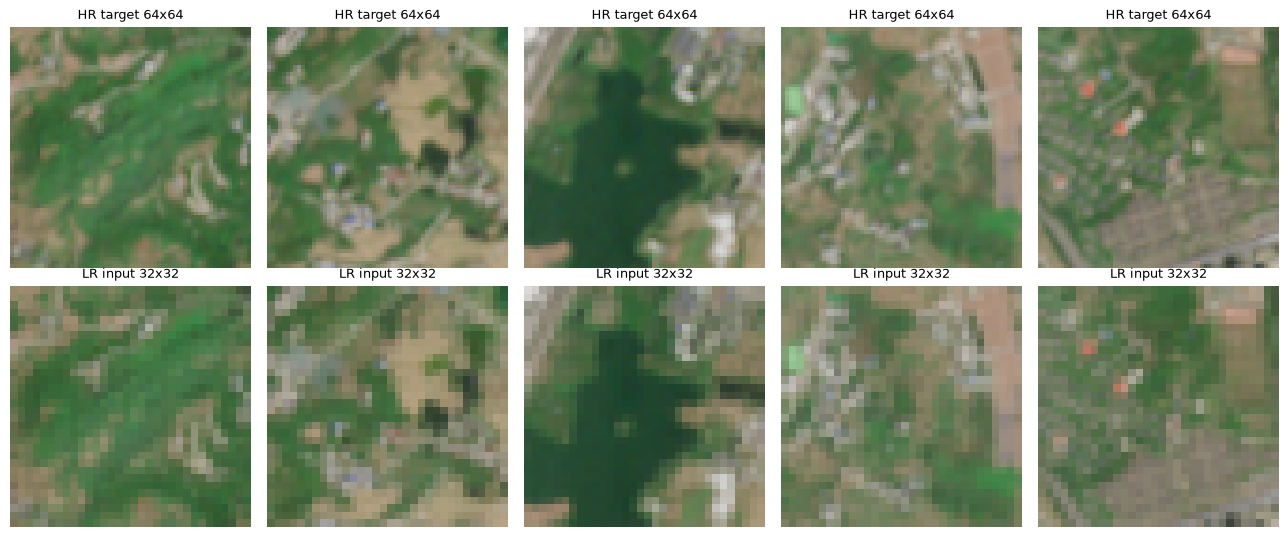

In [70]:
def extract_hr_patches(img, valid, x_range, stride, max_n, rng):
    x0, x1 = x_range
    coords = [(y, x) for y in range(0, H - HR_PATCH + 1, stride) for x in range(x0, x1 - HR_PATCH + 1, stride)]
    rng.shuffle(coords)
    out = []
    for y, x in coords:
        p = img[y:y + HR_PATCH, x:x + HR_PATCH]
        if patch_ok(p, valid[y:y + HR_PATCH, x:x + HR_PATCH]) and p.std() >= MIN_STD:
            out.append(p)
            if len(out) >= max_n:
                break
    if not out:
        raise RuntimeError("No usable patches in this band - use a larger / more detailed image or lower MIN_STD.")
    return np.stack(out)

x_tr_end, x_va_end = int(W * TRAIN_END), int(W * VAL_END)
rng = np.random.default_rng(SEED)
hr_tr = extract_hr_patches(hr_img, hr_valid, (0, x_tr_end),       SR_STRIDE, MAX_SR_TRAIN, rng)
hr_va = extract_hr_patches(hr_img, hr_valid, (x_tr_end, x_va_end), HR_PATCH, MAX_SR_VAL,   rng)

# test crops
crop = min(TEST_CROP, ((W - x_va_end) // (4 * SCALE)) * (4 * SCALE), (H // (4 * SCALE)) * (4 * SCALE))
if crop < 8 * SCALE * 4:
    raise RuntimeError("Test band too small - use a larger image.")
coords = [(y, x) for y in range(0, H - crop + 1, crop) for x in range(x_va_end, W - crop + 1, crop)]
rng.shuffle(coords)
hr_test = []
for y, x in coords:
    p = hr_img[y:y + crop, x:x + crop]
    if patch_ok(p, hr_valid[y:y + crop, x:x + crop]) and p.std() >= MIN_STD:
        hr_test.append(p)
    if len(hr_test) == N_TEST_CROPS:
        break
hr_test = np.stack(hr_test).astype(np.float32) / 255.0
print(f"train patches {hr_tr.shape}   val patches {hr_va.shape}   test crops {hr_test.shape}")

# what the network sees: HR target and LR input (shown with nearest-neighbour so that the pixels are visible)
fig, axes = plt.subplots(2, 5, figsize=(13, 5.4))
for c, i in enumerate(np.random.default_rng(1).choice(len(hr_tr), 5, replace=False)):
    hr = hr_tr[i]; lr = hr.reshape(LR_PATCH, SCALE, LR_PATCH, SCALE, 3).mean((1, 3))
    axes[0, c].imshow(hr, interpolation="nearest"); axes[0, c].set_title(f"HR target {HR_PATCH}x{HR_PATCH}", fontsize=9)
    axes[1, c].imshow(lr.astype(np.uint8), interpolation="nearest"); axes[1, c].set_title(f"LR input {LR_PATCH}x{LR_PATCH}", fontsize=9)
    axes[0, c].axis("off"); axes[1, c].axis("off")
plt.tight_layout(); plt.show()

In [71]:
# ----------------- data pipeline: HR patch -> (LR input, HR target) -----------------
def augment(x):
    x = tf.image.random_flip_left_right(x)
    x = tf.image.random_flip_up_down(x)
    return tf.image.rot90(x, tf.random.uniform([], 0, 4, dtype=tf.int32))

def downscale(hr):
    # SCALE x SCALE block averaging = AveragePooling2D(SCALE)
    return tf.nn.avg_pool2d(hr, ksize=SCALE, strides=SCALE, padding="VALID")

def upscale_bicubic(lr):
    size = tf.shape(lr)[1:3] * SCALE
    return tf.clip_by_value(tf.image.resize(lr, size, method="bicubic"), 0.0, 1.0)

def make_ds(hr_u8, kind, train):
    # kind = "lr": network input is the LR patch (M1);  kind = "bicubic": input is the bicubic-up-scaled LR patch (M2)
    ds = tf.data.Dataset.from_tensor_slices(hr_u8)
    if train:
        ds = ds.shuffle(len(hr_u8), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(lambda p: tf.cast(p, tf.float32) / 255.0, num_parallel_calls=tf.data.AUTOTUNE)
    if train and AUGMENT:
        ds = ds.map(augment, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(SR_BATCH)
    def pair(hr):
        lr = downscale(hr)
        return (lr if kind == "lr" else upscale_bicubic(lr)), hr
    return ds.map(pair, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)

# quick self-check of the shapes
xb, yb = next(iter(make_ds(hr_tr[:8], "lr", False)));       print("M1 batch:", xb.shape, "->", yb.shape)
xb, yb = next(iter(make_ds(hr_tr[:8], "bicubic", False)));  print("M2 batch:", xb.shape, "->", yb.shape)

M1 batch: (8, 32, 32, 3) -> (8, 64, 64, 3)
M2 batch: (8, 64, 64, 3) -> (8, 64, 64, 3)


## 8. The two networks

**M1 — the original autoencoder.** Autoencoder with layers (conv 16 → pool → conv 8 → pool | conv 8 → up → conv 8 → up → conv 16 → up → conv) and three colour channels in and out. The two pooling steps squeeze a 32 × 32 × 3 LR patch into an 8 × 8 × 8 code (512 numbers), and the decoder then has to draw a 64 × 64 × 3 HR patch from that code alone. That bottleneck is a good compressor, but fine detail has to survive it.

**M2 — a super-resolution autoencoder with two fixes.**

* **Skip connections.** Feature maps of the encoder are concatenated into the decoder, so fine detail does not have to pass through the bottleneck.
* **Residual learning.** The input is already the bicubic up-scaled image, and the network outputs a *correction* that is added to it. The last layer starts at zero, so M2 begins as bicubic interpolation and can only improve on it by learning real structure.

In [ ]:
L = tf.keras.layers

def build_m1_ae(f1=16, f2=8, scale=SCALE):
    # M1: the super-resolution autoencoder, RGB version (LR in -> HR out)
    inp = L.Input(shape=(None, None, 3))
    x = L.Conv2D(f1, 3, activation="relu", padding="same")(inp)
    x = L.MaxPooling2D(2, padding="same")(x)
    x = L.Conv2D(f2, 3, activation="relu", padding="same")(x)
    x = L.MaxPooling2D(2, padding="same")(x)                     # code: (h/4, w/4, f2)
    x = L.Conv2D(f2, 3, activation="relu", padding="same")(x)
    x = L.UpSampling2D(2)(x)
    x = L.Conv2D(f2, 3, activation="relu", padding="same")(x)
    x = L.UpSampling2D(2)(x)
    for _ in range(int(np.log2(scale))):                         # the extra up-sampling that makes it a super-resolver
        x = L.Conv2D(f1, 3, activation="relu", padding="same")(x)
        x = L.UpSampling2D(2)(x)
    out = L.Conv2D(3, 3, activation="sigmoid", padding="same")(x)
    return tf.keras.Model(inp, out, name="M1_AE")

def conv_block(x, f):
    x = L.Conv2D(f, 3, activation="relu", padding="same")(x)
    return L.Conv2D(f, 3, activation="relu", padding="same")(x)

def build_unet_residual(base=BASE_FILTERS, skips=True, residual=True):
    # M2: encoder-decoder with skip connections; input = bicubic-up-scaled LR image (HR size)
    inp = L.Input(shape=(None, None, 3))
    c1 = conv_block(inp, base)
    c2 = conv_block(L.MaxPooling2D(2)(c1), base * 2)
    b  = conv_block(L.MaxPooling2D(2)(c2), base * 4)
    u2 = L.UpSampling2D(2)(b)
    d2 = conv_block(L.Concatenate()([u2, c2]) if skips else u2, base * 2)
    u1 = L.UpSampling2D(2)(d2)
    d1 = conv_block(L.Concatenate()([u1, c1]) if skips else u1, base)
    if residual:
        res = L.Conv2D(3, 3, padding="same", kernel_initializer="zeros")(d1)   # starts as "output = bicubic input"
        out = L.Add()([inp, res])
    else:
        out = L.Conv2D(3, 3, padding="same", activation="sigmoid")(d1)
    return tf.keras.Model(inp, out, name="M2_unet_residual")

m1_probe = build_m1_ae()
print(f"M1: {m1_probe.count_params():,} parameters;  code size {LR_PATCH // 4} x {LR_PATCH // 4} x 8 = {(LR_PATCH // 4) ** 2 * 8} numbers "
      f"for a {LR_PATCH} x {LR_PATCH} x 3 = {LR_PATCH ** 2 * 3} input")
print(f"M2: {build_unet_residual().count_params():,} parameters")
m1_probe.summary()

M1: 4,379 parameters;  code size 8 x 8 x 8 = 512 numbers for a 32 x 32 x 3 = 3072 input
M2: 472,387 parameters


Model: "M1_AE"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_15 (InputLayer)     │ (None, None, None, 3)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_125 (Conv2D)             │ (None, None, None, 16) │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_30 (MaxPooling2D) │ (None, None, None, 16) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_126 (Conv2D)             │ (None, None, None, 8)  │         1,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_31 (MaxPooling2D) │ (None, None, None, 8)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_127 (Conv2D)             │ (None, None, None, 8)  │           584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_38 (UpSampling2D) │ (None, None, None, 8)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_128 (Conv2D)             │ (None, None, None, 8)  │           584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_39 (UpSampling2D) │ (None, None, None, 8)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_129 (Conv2D)             │ (None, None, None, 16) │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_40 (UpSampling2D) │ (None, None, None, 16) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_130 (Conv2D)             │ (None, None, None, 3)  │           435 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,379 (17.11 KB)

 Trainable params: 4,379 (17.11 KB)

 Non-trainable params: 0 (0.00 B)

In [73]:
HIST, SR_MODELS = {}, {}

def train_model(model, kind, loss, epochs=SR_EPOCHS):
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss=loss, metrics=["mse"])
    cbs = [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=SR_PATIENCE, restore_best_weights=True),
           tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5)]
    t0 = time.time()
    h = model.fit(make_ds(hr_tr, kind, True), validation_data=make_ds(hr_va, kind, False),
                  epochs=epochs, callbacks=cbs, shuffle=False, verbose=2)
    return h.history, time.time() - t0

M1_NAME, M2_NAME = "M1 AE", "M2 U-Net + residual"

# ---- M1: architecture, binary cross-entropy
set_seed(SEED)
m1 = build_m1_ae()
HIST[M1_NAME], T_M1 = train_model(m1, "lr", "binary_crossentropy")
SR_MODELS[M1_NAME] = (m1, "lr")
print(f"\n{M1_NAME}: {len(HIST[M1_NAME]['loss'])} epochs, {T_M1:.0f} s")

Epoch 1/30
71/71 - 4s - 63ms/step - loss: 0.6797 - mse: 0.0134 - val_loss: 0.6534 - val_mse: 0.0063 - learning_rate: 0.0010
Epoch 2/30
71/71 - 2s - 31ms/step - loss: 0.6659 - mse: 0.0067 - val_loss: 0.6500 - val_mse: 0.0047 - learning_rate: 0.0010
Epoch 3/30
71/71 - 2s - 31ms/step - loss: 0.6641 - mse: 0.0058 - val_loss: 0.6488 - val_mse: 0.0042 - learning_rate: 0.0010
Epoch 4/30
71/71 - 2s - 32ms/step - loss: 0.6631 - mse: 0.0054 - val_loss: 0.6481 - val_mse: 0.0039 - learning_rate: 0.0010
Epoch 5/30
71/71 - 2s - 33ms/step - loss: 0.6623 - mse: 0.0050 - val_loss: 0.6473 - val_mse: 0.0035 - learning_rate: 0.0010
Epoch 6/30
71/71 - 2s - 31ms/step - loss: 0.6617 - mse: 0.0047 - val_loss: 0.6469 - val_mse: 0.0033 - learning_rate: 0.0010
Epoch 7/30
71/71 - 2s - 26ms/step - loss: 0.6612 - mse: 0.0045 - val_loss: 0.6466 - val_mse: 0.0032 - learning_rate: 0.0010
Epoch 8/30
71/71 - 2s - 32ms/step - loss: 0.6608 - mse: 0.0043 - val_loss: 0.6463 - val_mse: 0.0030 - learning_rate: 0.0010
Epoch 9/

Epoch 1/30
71/71 - 27s - 374ms/step - loss: 0.0129 - mse: 3.2940e-04 - val_loss: 0.0085 - val_mse: 1.6540e-04 - learning_rate: 0.0010
Epoch 2/30
71/71 - 23s - 327ms/step - loss: 0.0117 - mse: 2.7033e-04 - val_loss: 0.0081 - val_mse: 1.5130e-04 - learning_rate: 0.0010
Epoch 3/30
71/71 - 24s - 331ms/step - loss: 0.0113 - mse: 2.5629e-04 - val_loss: 0.0079 - val_mse: 1.4387e-04 - learning_rate: 0.0010
Epoch 4/30
71/71 - 24s - 333ms/step - loss: 0.0111 - mse: 2.4909e-04 - val_loss: 0.0078 - val_mse: 1.4040e-04 - learning_rate: 0.0010
Epoch 5/30
71/71 - 23s - 327ms/step - loss: 0.0110 - mse: 2.4382e-04 - val_loss: 0.0077 - val_mse: 1.3806e-04 - learning_rate: 0.0010
Epoch 6/30
71/71 - 24s - 339ms/step - loss: 0.0109 - mse: 2.4074e-04 - val_loss: 0.0077 - val_mse: 1.3642e-04 - learning_rate: 0.0010
Epoch 7/30
71/71 - 23s - 331ms/step - loss: 0.0109 - mse: 2.3765e-04 - val_loss: 0.0077 - val_mse: 1.3521e-04 - learning_rate: 0.0010
Epoch 8/30
71/71 - 23s - 327ms/step - loss: 0.0108 - mse: 2.34

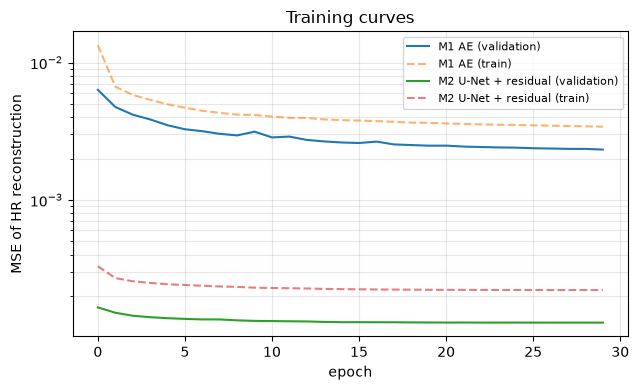

In [74]:
# ---- M2: skip connections + residual output, L1 loss
set_seed(SEED)
m2 = build_unet_residual()
HIST[M2_NAME], T_M2 = train_model(m2, "bicubic", "mae")
SR_MODELS[M2_NAME] = (m2, "bicubic")
print(f"\n{M2_NAME}: {len(HIST[M2_NAME]['loss'])} epochs, {T_M2:.0f} s")

# validation MSE is the one quantity that is comparable between the two losses
plt.figure(figsize=(6.5, 4))
for n, h in HIST.items():
    plt.plot(h["val_mse"], label=f"{n} (validation)"); plt.plot(h["mse"], "--", alpha=.6, label=f"{n} (train)")
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("MSE of HR reconstruction"); plt.grid(alpha=.3, which="both"); plt.legend(fontsize=8)
plt.title("Training curves"); plt.tight_layout(); plt.show()

## 9. Evaluation on the held-out test band

Every test crop (HR, known) is shrunk to LR, super-resolved by each method, and compared with the original crop. Metrics:

* **PSNR** (dB, higher = better) and **SSIM** (0 … 1, higher = better), averaged over the test crops (± standard deviation across crops);
* **crops better than bicubic**: in how many crops the method beats the bicubic baseline. A mean gain that comes from one lucky crop should not be trusted.

In [75]:
def sr_predict(model, kind, lr):
    x = lr if kind == "lr" else upscale_bicubic(tf.constant(lr)).numpy()
    return np.clip(model.predict(x, batch_size=4, verbose=0), 0.0, 1.0)

def image_metrics(hr, sr):
    return (tf.image.psnr(hr, sr, max_val=1.0).numpy(), tf.image.ssim(hr, sr, max_val=1.0).numpy())

lr_test = downscale(tf.constant(hr_test)).numpy()
SR, RES = {}, {}

def register(name, sr, params=None, secs=None):
    ps, ss = image_metrics(hr_test, sr)
    SR[name] = sr; RES[name] = dict(psnr=ps, ssim=ss, params=params, secs=secs)

register("nearest",  np.repeat(np.repeat(lr_test, SCALE, 1), SCALE, 2))
register("bicubic",  upscale_bicubic(tf.constant(lr_test)).numpy())
register(M1_NAME, sr_predict(m1, "lr", lr_test),          m1.count_params(), T_M1)
register(M2_NAME, sr_predict(m2, "bicubic", lr_test),     m2.count_params(), T_M2)

def results_table():
    base = RES["bicubic"]["psnr"]
    rows = [{"method": n, "params": r["params"], "train time [s]": r["secs"],
             "PSNR [dB]": f"{r['psnr'].mean():.2f} ± {r['psnr'].std():.2f}",
             "gain vs bicubic [dB]": r["psnr"].mean() - base.mean(),
             "SSIM": f"{r['ssim'].mean():.4f} ± {r['ssim'].std():.4f}",
             "crops better than bicubic": "reference" if n == "bicubic" else f"{int((r['psnr'] > base).sum())}/{len(base)}"} for n, r in RES.items()]
    return pd.DataFrame(rows).style.hide(axis="index").format(
        {"params": "{:,.0f}", "train time [s]": "{:.0f}", "gain vs bicubic [dB]": "{:+.2f}"}, na_rep="–")

print(f"{len(hr_test)} test crops of {hr_test.shape[1]} x {hr_test.shape[2]} px, x{SCALE} up-scaling")
results_table()

8 test crops of 256 x 256 px, x2 up-scaling


method,params,train time [s],PSNR [dB],gain vs bicubic [dB],SSIM,crops better than bicubic
nearest,–,–,31.80 ± 1.14,-3.15,0.8991 ± 0.0151,0/8
bicubic,–,–,34.95 ± 1.16,+0.00,0.9418 ± 0.0088,reference
M1 AE,"4,379",68,25.35 ± 0.96,-9.59,0.6117 ± 0.0638,0/8
M2 U-Net + residual,"472,387",693,37.61 ± 1.29,+2.66,0.9671 ± 0.0052,8/8


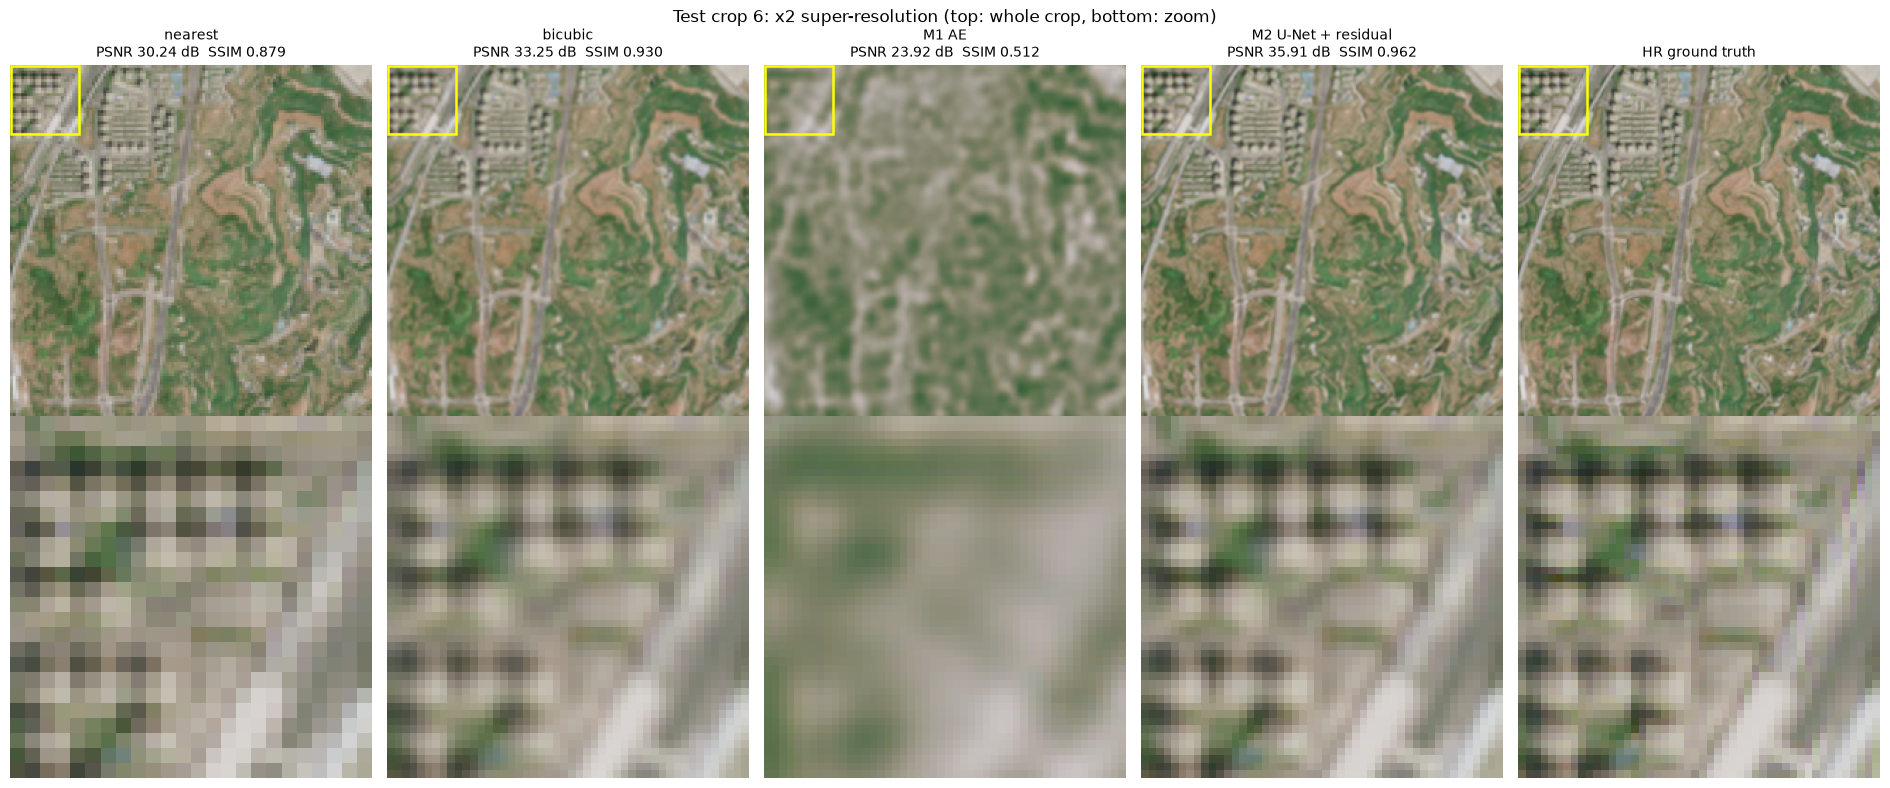

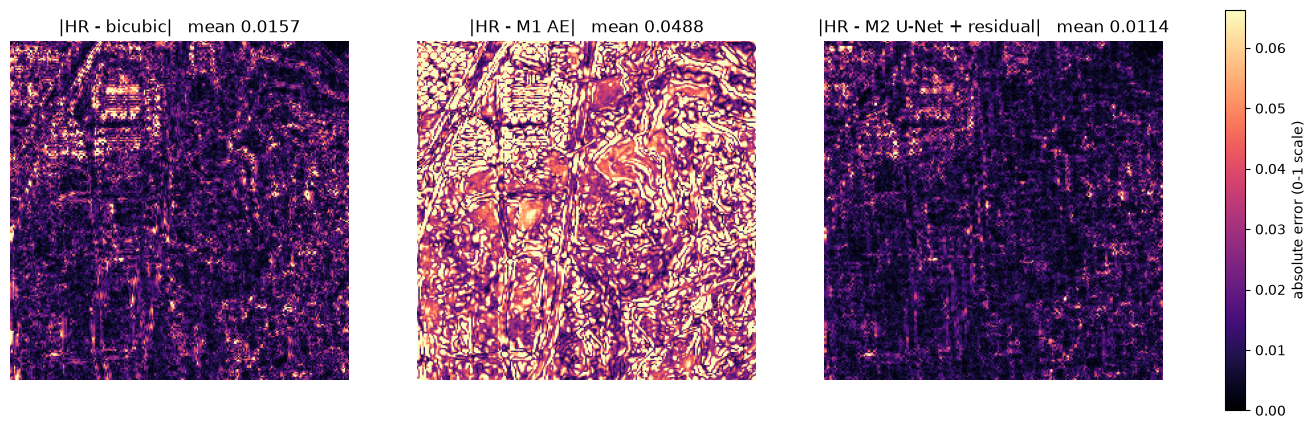

In [76]:
# Visual comparison on the most detailed test crop; yellow box = zoom window (shown with nearest-neighbour pixels)
def grad_energy(a):
    g = a.mean(-1)
    return np.abs(np.diff(g, axis=0)).mean() + np.abs(np.diff(g, axis=1)).mean()

def best_window(img, size=48, step=8):
    g = img.mean(-1)
    e = np.abs(np.diff(g, axis=0))[:, :-1] + np.abs(np.diff(g, axis=1))[:-1, :]
    best, pos = -1, (0, 0)
    for y in range(0, e.shape[0] - size + 1, step):
        for x in range(0, e.shape[1] - size + 1, step):
            v = e[y:y + size, x:x + size].mean()
            if v > best:
                best, pos = v, (y, x)
    return pos

def show_comparison(j, zoom=48):
    names = ["nearest", "bicubic", M1_NAME, M2_NAME, "HR ground truth"]
    imgs  = [SR["nearest"][j], SR["bicubic"][j], SR[M1_NAME][j], SR[M2_NAME][j], hr_test[j]]
    y, x = best_window(hr_test[j], zoom)
    fig, axes = plt.subplots(2, 5, figsize=(19, 8))
    for k, (n, im) in enumerate(zip(names, imgs)):
        t = n if n.startswith("HR") else f"{n}\nPSNR {RES[n]['psnr'][j]:.2f} dB  SSIM {RES[n]['ssim'][j]:.3f}"
        axes[0, k].imshow(im); axes[0, k].set_title(t, fontsize=10)
        axes[0, k].add_patch(Rectangle((x, y), zoom, zoom, fill=False, ec="yellow", lw=1.8))
        axes[1, k].imshow(im[y:y + zoom, x:x + zoom], interpolation="nearest")
        axes[0, k].axis("off"); axes[1, k].axis("off")
    plt.suptitle(f"Test crop {j}: x{SCALE} super-resolution (top: whole crop, bottom: zoom)"); plt.tight_layout(); plt.show()

j_best = int(np.argmax([grad_energy(c) for c in hr_test]))
show_comparison(j_best)

# error maps: |HR - SR| averaged over colour channels, shared colour scale
errs = {n: np.abs(hr_test[j_best] - SR[n][j_best]).mean(-1) for n in ["bicubic", M1_NAME, M2_NAME]}
vmax = np.percentile(errs["bicubic"], 99)
fig, axes = plt.subplots(1, 3, figsize=(16, 5.2))
for ax, (n, e) in zip(axes, errs.items()):
    im = ax.imshow(e, cmap="magma", vmin=0, vmax=vmax); ax.axis("off"); ax.set_title(f"|HR - {n}|   mean {e.mean():.4f}")
fig.colorbar(im, ax=axes, fraction=0.02, label="absolute error (0-1 scale)"); plt.show()

### Power spectrum:

An image shrunk by `SCALE` can no longer represent spatial frequencies above $0.5/\text{SCALE}$ cycles per HR pixel (dashed line). Interpolation cannot invent them, so the bicubic curve falls away to the right of that line. A super-resolver that really restores detail should lift its curve towards the HR (ground-truth) curve in the band between the dashed line and 0.5 cycles/pixel. Curves that rise above the HR curve mean artefacts (ringing, checkerboard patterns, invented texture), not detail.

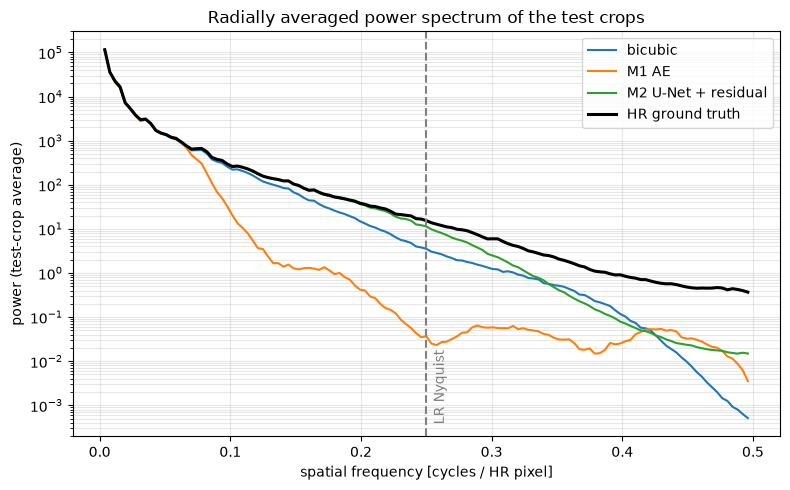

In [77]:
def radial_psd(gray):
    # radially averaged power spectrum of a 2-D image (Hann-windowed); returns (frequency in cycles/pixel, power)
    h, w = gray.shape
    P = np.abs(np.fft.fftshift(np.fft.fft2((gray - gray.mean()) * np.outer(np.hanning(h), np.hanning(w))))) ** 2
    yy, xx = np.indices(P.shape)
    r = np.hypot(yy - h // 2, xx - w // 2).astype(int)
    n = min(h, w) // 2
    tot = np.bincount(r.ravel(), P.ravel(), minlength=n + 1)[:n]
    cnt = np.maximum(np.bincount(r.ravel(), minlength=n + 1)[:n], 1)
    return np.arange(n) / min(h, w), tot / cnt

lum = np.array([0.299, 0.587, 0.114], dtype=np.float32)
curves = {}
for n in ["bicubic", M1_NAME, M2_NAME, "HR ground truth"]:
    arr = hr_test if n.startswith("HR") else SR[n]
    ps = [radial_psd(a @ lum) for a in arr]
    curves[n] = (ps[0][0], np.mean([p[1] for p in ps], axis=0))

plt.figure(figsize=(8, 5))
for n, (f, p) in curves.items():
    plt.semilogy(f[1:], p[1:], lw=2.2 if n.startswith("HR") else 1.5, label=n,
                 color="k" if n.startswith("HR") else None)
plt.axvline(0.5 / SCALE, color="gray", ls="--"); plt.text(0.5 / SCALE + 0.005, 0.03, "LR Nyquist", color="gray", rotation=90, va="bottom", transform=plt.gca().get_xaxis_transform())
plt.xlabel("spatial frequency [cycles / HR pixel]"); plt.ylabel("power (test-crop average)"); plt.grid(alpha=.3, which="both"); plt.legend()
plt.title("Radially averaged power spectrum of the test crops"); plt.tight_layout(); plt.show()

## 10. Applying it to the image at its native resolution

native window: rows 128..256, cols 1839..1967  ->  output 256 x 256


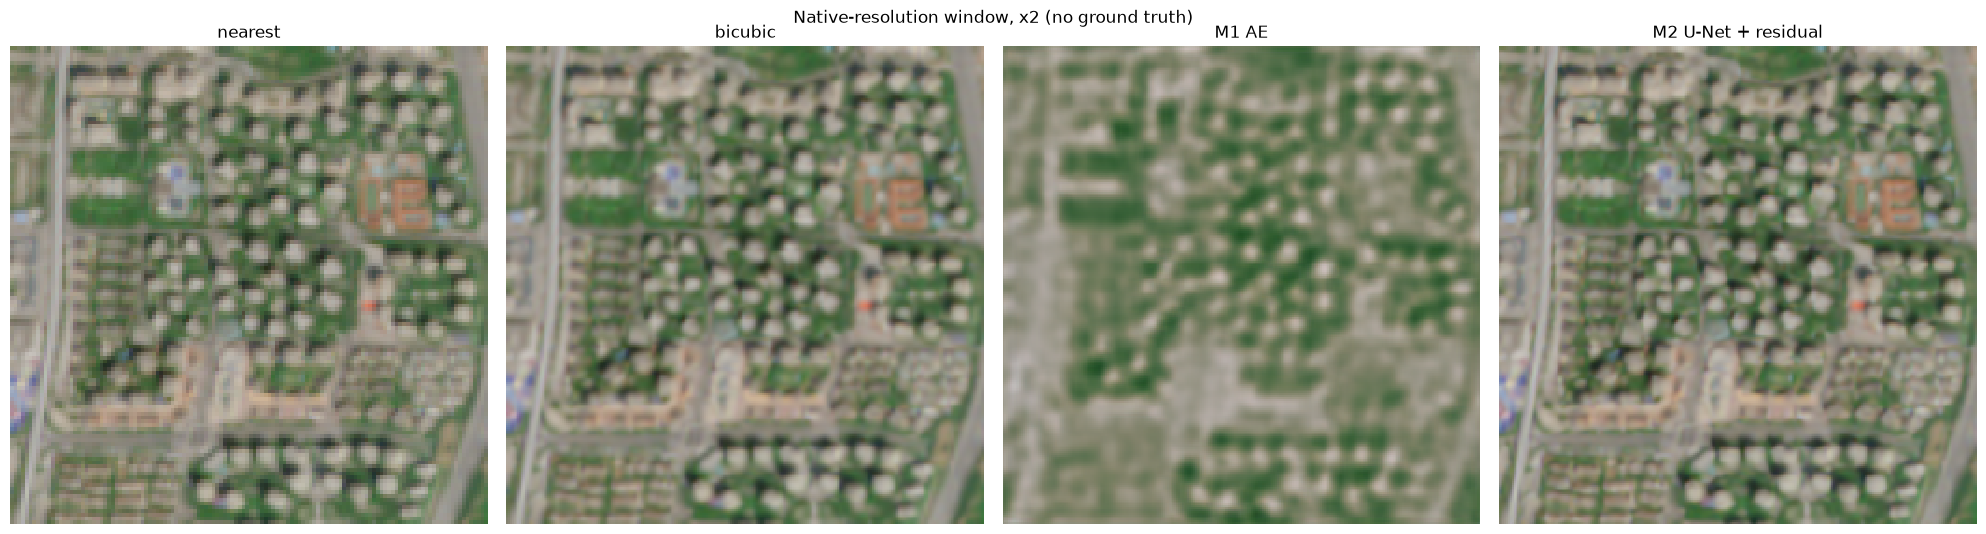

method,MSE after block-averaging back to the native grid,share of spectral power above native Nyquist
nearest,0.00e+00,2.28e-03
bicubic,3.05e-05,7.86e-05
M1 AE,2.84e-03,3.55e-05
M2 U-Net + residual,1.47e-06,1.43e-04


In [79]:
# choose the window (most detailed part of the test band) unless ROI is given
if ROI is None:
    best, ROI = -1, (0, x_va_end)
    for y in range(0, H - ROI_SIZE + 1, ROI_SIZE // 2):
        for x in range(x_va_end, W - ROI_SIZE + 1, ROI_SIZE // 2):
            p = hr_img[y:y + ROI_SIZE, x:x + ROI_SIZE]
            if patch_ok(p, hr_valid[y:y + ROI_SIZE, x:x + ROI_SIZE]):
                e = grad_energy(p.astype(np.float32))
                if e > best:
                    best, ROI = e, (y, x)
ry, rx = ROI
roi = (hr_img[ry:ry + ROI_SIZE, rx:rx + ROI_SIZE].astype(np.float32) / 255.0)[None]
print(f"native window: rows {ry}..{ry + ROI_SIZE}, cols {rx}..{rx + ROI_SIZE}  ->  output {ROI_SIZE * SCALE} x {ROI_SIZE * SCALE}")

OUT = {"nearest": np.repeat(np.repeat(roi, SCALE, 1), SCALE, 2),
       "bicubic": upscale_bicubic(tf.constant(roi)).numpy(),
       M1_NAME: sr_predict(m1, "lr", roi),
       M2_NAME: sr_predict(m2, "bicubic", roi)}

fig, axes = plt.subplots(1, 4, figsize=(20, 5.4))
for ax, (n, im) in zip(axes, OUT.items()):
    ax.imshow(im[0], interpolation="nearest"); ax.set_title(n); ax.axis("off")
plt.suptitle(f"Native-resolution window, x{SCALE} (no ground truth)"); plt.tight_layout(); plt.show()

# consistency check and spectral content beyond the native Nyquist frequency
rows = []
for n, im in OUT.items():
    back = downscale(tf.constant(im)).numpy()
    f, p = radial_psd(im[0] @ lum)
    hf = p[f > 0.5 / SCALE].sum() / p[1:].sum()
    rows.append({"method": n, "MSE after block-averaging back to the native grid": float(np.mean((back - roi) ** 2)),
                 "share of spectral power above native Nyquist": hf})
display(pd.DataFrame(rows).style.hide(axis="index").format({"MSE after block-averaging back to the native grid": "{:.2e}",
                                                            "share of spectral power above native Nyquist": "{:.2e}"}))

## 11. Discussion

The M1 autoencoder did not enhance the resolution of the image, instead it has worsened it. It is due to the small capacity of the filters and a structure that bottlenecks the data. The program has a hard time predictng the details and gives blurry results. The implemented changes in M2 provide a much better result, being better then bicubic up-scaling, which is predictible as it works off of it.